In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
orders=pd.read_csv('input/data_orders.csv')

In [5]:
orders.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0
4,21:24:45,-0.967605,51.458236,NaN,3000583140877,9,0,NaN


In [6]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 10716 entries, 0 to 10715
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_datetime                 10716 non-null  str    
 1   origin_longitude               10716 non-null  float64
 2   origin_latitude                10716 non-null  float64
 3   m_order_eta                    2814 non-null   float64
 4   order_gk                       10716 non-null  int64  
 5   order_status_key               10716 non-null  int64  
 6   is_driver_assigned_key         10716 non-null  int64  
 7   cancellations_time_in_seconds  7307 non-null   float64
dtypes: float64(4), int64(3), str(1)
memory usage: 753.6 KB


order_datetime - time of the order  
origin_longitude - longitude of the order  
origin_latitude - latitude of the order  
m_order_eta - time before order arrival  
order_gk - order number  
order_status_key - status, an enumeration consisting of the following mapping:  
4 - cancelled by client,  
9 - cancelled by system, i.e., a reject  
is_driver_assigned_key - whether a driver has been assigned  
cancellation_time_in_seconds - how many seconds passed before cancellation  

# Part 1.

- Build up distribution of orders according to reasons for failure: cancellations before and after driver assignment, and reasons for order rejection. Analyse the resulting plot. Which category has the highest number of orders?

In [7]:
orders['order_status_key'].value_counts()

order_status_key
4    7307
9    3409
Name: count, dtype: int64

In [8]:
orders.groupby(['order_status_key','is_driver_assigned_key'],as_index=False).agg(total_orders=('order_gk','count'))

,order_status_key,is_driver_assigned_key,total_orders
0,4,0,4496
1,4,1,2811
2,9,0,3406
3,9,1,3


In [9]:
canceled_by_customer=orders[orders['order_status_key']==4]
canceled_by_customer

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0
9,06:33:52,-0.976216,51.433202,NaN,3000582765616,4,0,78.0
...,...,...,...,...,...,...,...,...
10711,13:11:35,-0.975372,51.457846,NaN,3000599186906,4,0,36.0
10712,13:13:55,-0.975372,51.457846,NaN,3000599186962,4,0,4.0
10713,13:17:21,-0.972926,51.457693,60.0,3000599187034,4,1,34.0
10714,13:16:28,-0.975372,51.457846,NaN,3000599187024,4,0,6.0


In [10]:
canceled_by_customer_driver_not_assigned=canceled_by_customer.query('is_driver_assigned_key==0')
canceled_by_customer_driver_not_assigned

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0
9,06:33:52,-0.976216,51.433202,NaN,3000582765616,4,0,78.0
10,15:40:15,-0.934670,51.447065,NaN,3000582991062,4,0,167.0
11,20:59:35,-0.972735,51.452489,NaN,3000583116472,4,0,45.0
12,06:25:31,-0.958791,51.459481,NaN,3000582765488,4,0,79.0
...,...,...,...,...,...,...,...,...
10709,12:44:11,-0.975372,51.457846,NaN,3000597886155,4,0,43.0
10710,12:42:52,-0.975372,51.457846,NaN,3000597886140,4,0,44.0
10711,13:11:35,-0.975372,51.457846,NaN,3000599186906,4,0,36.0
10712,13:13:55,-0.975372,51.457846,NaN,3000599186962,4,0,4.0


<Axes: ylabel='Frequency'>

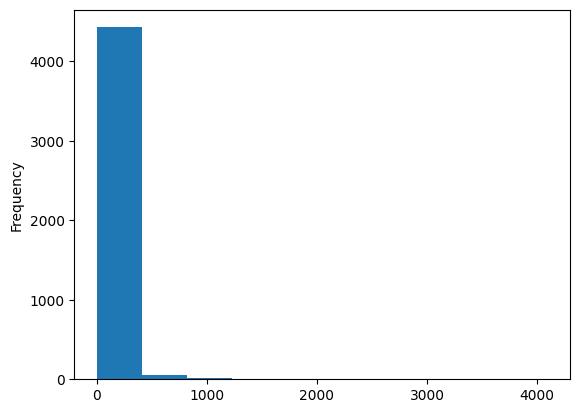

In [11]:
canceled_by_customer_driver_not_assigned['cancellations_time_in_seconds'].plot(kind='hist')

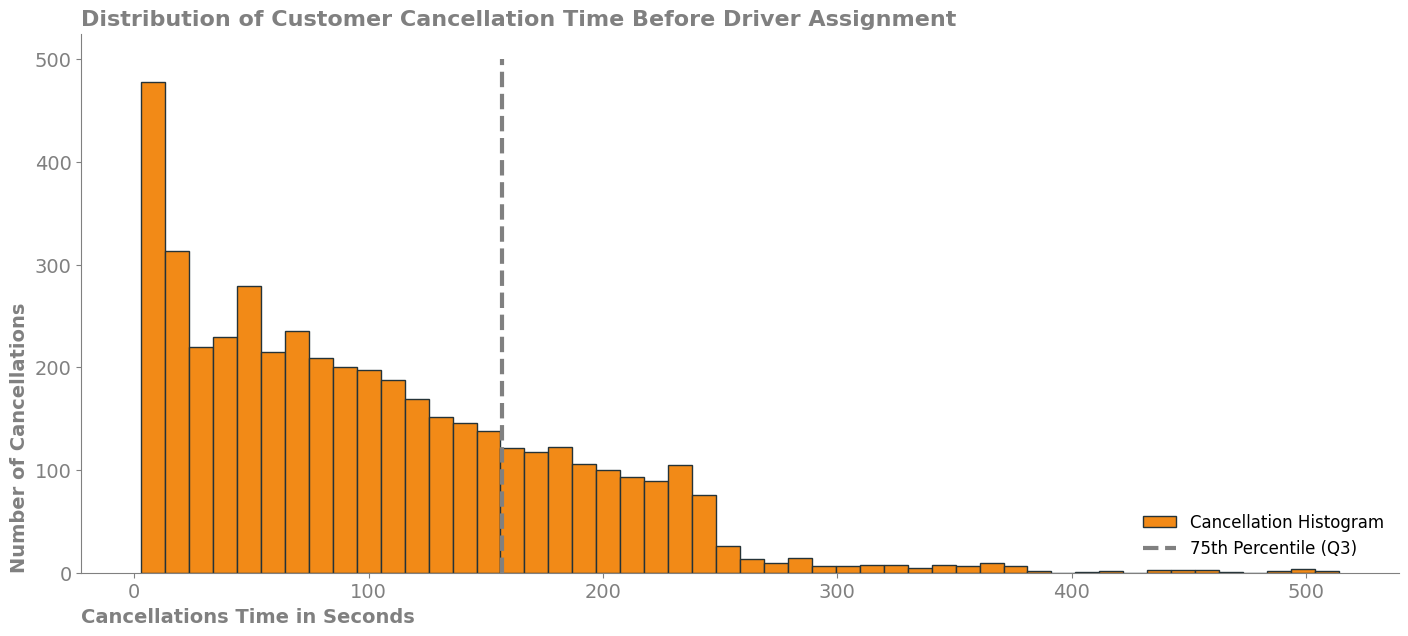

In [12]:
fig,ax=plt.subplots(figsize=(17,7))
ax.hist(canceled_by_customer_driver_not_assigned.query('cancellations_time_in_seconds<522')['cancellations_time_in_seconds'],
        bins=50,
        color="#F28A17",
        edgecolor="#253338",
        label='Cancellation Histogram')

ax.vlines(canceled_by_customer_driver_not_assigned['cancellations_time_in_seconds'].quantile(0.75),
        ymin=0,
        ymax=500,
        color='gray',
        linestyle='dashed',
        linewidth=3,
        label='75th Percentile (Q3)')
ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.set_xlabel("Cancellations Time in Seconds", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Number of Cancellations", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title('Distribution of Customer Cancellation Time Before Driver Assignment',fontsize=16,color="gray",loc="left",weight="bold")

ax.tick_params(axis='both',colors='gray',labelsize=14)
ax.legend(loc='lower right' , frameon=False , fontsize=12)
plt.show()

In [13]:
canceled_by_customer_driver_not_assigned['cancellations_time_in_seconds'].quantile(0.99)

np.float64(522.7000000000025)

In [14]:
canceled_by_customer_driver_not_assigned[canceled_by_customer_driver_not_assigned['cancellations_time_in_seconds']>=522].shape[0]

46

In [15]:
canceled_by_customer_driver_not_assigned['cancellations_time_in_seconds'].describe()

count    4496.000000
mean      110.371441
std       120.676021
min         3.000000
25%        38.000000
50%        88.000000
75%       157.000000
max      4097.000000
Name: cancellations_time_in_seconds, dtype: float64

In [16]:
canceled_by_customer_long_eta=canceled_by_customer.query('is_driver_assigned_key==1 and m_order_eta > cancellations_time_in_seconds')
canceled_by_customer_long_eta.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0
13,16:55:28,-0.950683,51.451368,538.0,3000583016613,4,1,188.0
21,12:57:52,-0.933755,51.446834,117.0,3000582916315,4,1,41.0
22,08:37:53,-0.972037,51.456781,898.0,3000582816590,4,1,101.0


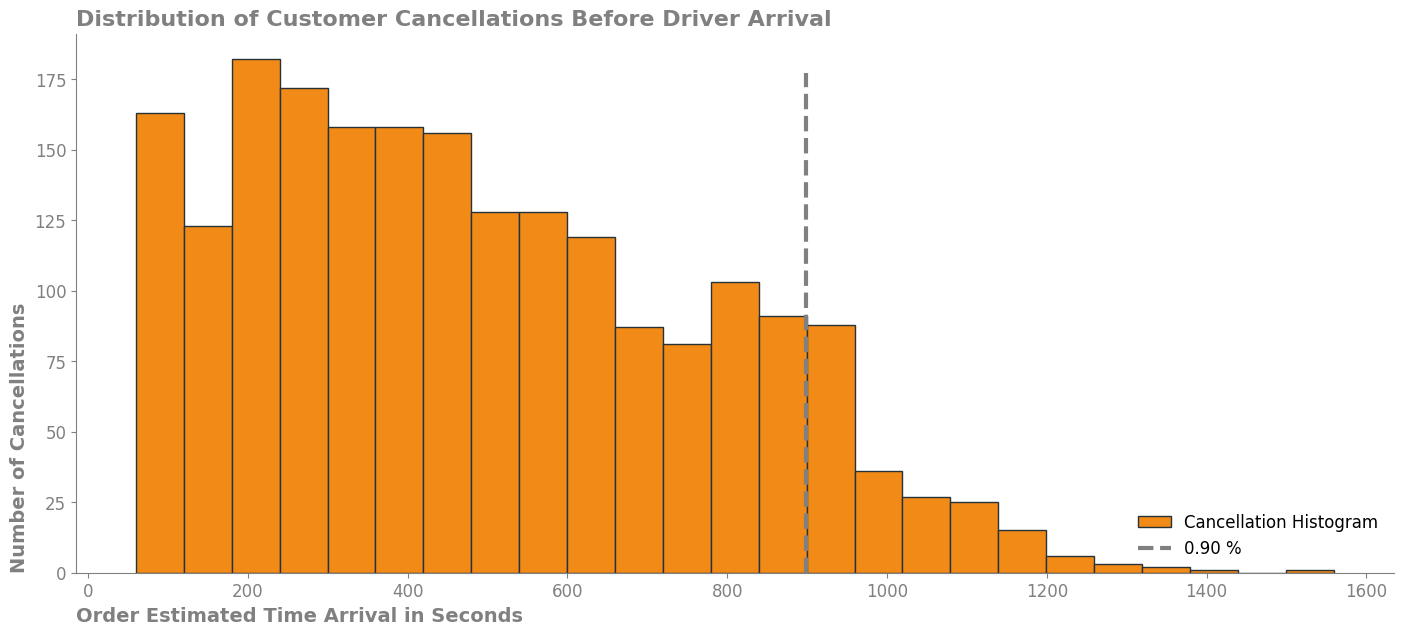

In [17]:
fig,ax=plt.subplots(figsize=(17,7))
ax.hist(canceled_by_customer_long_eta['m_order_eta'],
        bins=25,
        color="#F28A17",
        edgecolor="#253338",
        label="Cancellation Histogram")

ax.vlines(canceled_by_customer_long_eta['m_order_eta'].quantile(0.9),
        ymin=0,
        ymax=177,
        linestyles='dashed',
        colors='gray',
        linewidth=3,
        label='0.90 %')

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.tick_params(axis="both", colors="gray", labelsize=12)

ax.set_xlabel("Order Estimated Time Arrival in Seconds", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Number of Cancellations", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title('Distribution of Customer Cancellations Before Driver Arrival',fontsize=16, color="gray", loc="left", weight="bold")

plt.legend(loc="lower right", fontsize=12,frameon=False)
plt.show()

In [18]:
canceled_by_customer_long_eta['m_order_eta'].describe()

count    2053.000000
mean      513.623478
std       284.263979
min        60.000000
25%       297.000000
50%       478.000000
75%       718.000000
max      1559.000000
Name: m_order_eta, dtype: float64

In [19]:
canceled_by_customer_after_eta=canceled_by_customer.query('is_driver_assigned_key==1 and cancellations_time_in_seconds >m_order_eta')
canceled_by_customer_after_eta.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0
14,00:59:26,-0.937006,51.448696,179.0,3000582566041,4,1,316.0
20,13:21:15,-0.978916,51.456173,60.0,3000582916858,4,1,475.0
28,22:41:17,-0.963063,51.449616,178.0,3000632496461,4,1,527.0
51,14:40:45,-0.982604,51.471714,237.0,3000632296105,4,1,418.0


In [20]:
canceled_by_customer_after_eta['cancellation_after_driver_arrived']=(
    canceled_by_customer_after_eta['cancellations_time_in_seconds']-canceled_by_customer_after_eta['m_order_eta'])

In [21]:
canceled_by_customer_after_eta.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,cancellation_after_driver_arrived
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,138.0
14,00:59:26,-0.937006,51.448696,179.0,3000582566041,4,1,316.0,137.0
20,13:21:15,-0.978916,51.456173,60.0,3000582916858,4,1,475.0,415.0
28,22:41:17,-0.963063,51.449616,178.0,3000632496461,4,1,527.0,349.0
51,14:40:45,-0.982604,51.471714,237.0,3000632296105,4,1,418.0,181.0


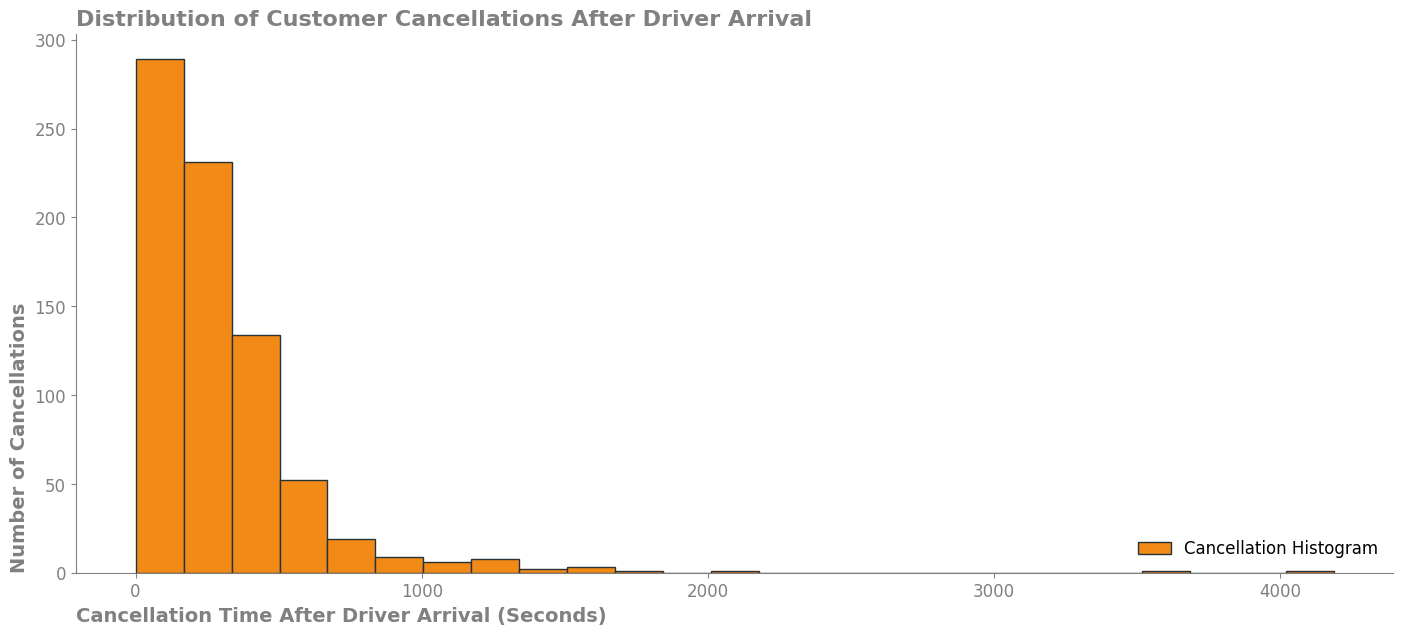

In [22]:
fig,ax=plt.subplots(figsize=(17,7))
ax.hist(canceled_by_customer_after_eta['cancellation_after_driver_arrived'],
        bins=25,
        color="#F28A17",
        edgecolor="#253338",
        label="Cancellation Histogram")

ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')
ax.tick_params(axis="both", colors="gray", labelsize=12)

ax.set_xlabel("Cancellation Time After Driver Arrival (Seconds)", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Number of Cancellations", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title('Distribution of Customer Cancellations After Driver Arrival',fontsize=16, color="gray", loc="left", weight="bold")
ax.legend(loc='lower right', frameon=False, fontsize=12)

plt.show()

In [23]:
canceled_by_system=orders[(orders['order_status_key']==9) & (orders['is_driver_assigned_key']==0)]
canceled_by_system.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
4,21:24:45,-0.967605,51.458236,NaN,3000583140877,9,0,NaN
5,21:21:23,-0.947011,51.456380,NaN,3000583117054,9,0,NaN
6,07:58:15,-0.955637,51.470372,NaN,3000582791789,9,0,NaN
7,07:53:46,-0.978230,51.454575,NaN,3000582791562,9,0,NaN
8,08:53:01,-1.052298,51.454308,NaN,3000582817606,9,0,NaN


In [24]:
orders[(orders['order_status_key']==9) & (orders['is_driver_assigned_key']==1)]

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
1158,16:49:55,-0.974337,51.465422,418.0,3000631256425,9,1,NaN
6881,00:44:03,-0.973348,51.453919,60.0,3000630156338,9,1,NaN
7968,00:12:02,-0.974735,51.454823,298.0,3000600112433,9,1,NaN


# part 2
- Plot the distribution of failed orders by hours. Is there a trend that certain hours have an abnormally high proportion of one category or another? What hours are the biggest fails? How can this be explained? 

In [25]:
orders['order_hour']=orders['order_datetime'].str.split(':').str.get(0).astype('int8')
orders['order_hour']

0        18
1        20
2        12
3        13
4        21
         ..
10711    13
10712    13
10713    13
10714    13
10715    11
Name: order_hour, Length: 10716, dtype: int8

In [26]:
(orders['order_hour'].value_counts()
                    .reset_index()
                    .sort_values('order_hour')
                    .rename(columns={'count':'total_failed_orders'})
                    .reset_index(drop=True))

,order_hour,total_failed_orders
0,0,683
1,1,471
2,2,555
3,3,513
4,4,152
5,5,67
6,6,159
7,7,447
8,8,1082
9,9,412


In [27]:
hourly_canceled_orders=(orders.groupby('order_hour',as_index=False).agg(total_failed_orders=('order_gk', 'count'))
                        .assign(share_canceled_orders=lambda df:df['total_failed_orders']/df['total_failed_orders'].sum(),
                                total_canceled_orders_zscore=lambda df:stats.zscore(df['total_failed_orders']),
                                hour_color=lambda df:np.where(df['total_canceled_orders_zscore']>1,"#F28A17", "#253338")))
hourly_canceled_orders

,order_hour,total_failed_orders,share_canceled_orders,total_canceled_orders_zscore,hour_color
0,0,683,0.063736,0.968738,#253338
1,1,471,0.043953,0.100356,#253338
2,2,555,0.051792,0.444432,#253338
3,3,513,0.047872,0.272394,#253338
4,4,152,0.014184,-1.206315,#253338
5,5,67,0.006252,-1.554487,#253338
6,6,159,0.014838,-1.177642,#253338
7,7,447,0.041713,0.002048,#253338
8,8,1082,0.100971,2.603100,#F28A17
9,9,412,0.038447,-0.141317,#253338


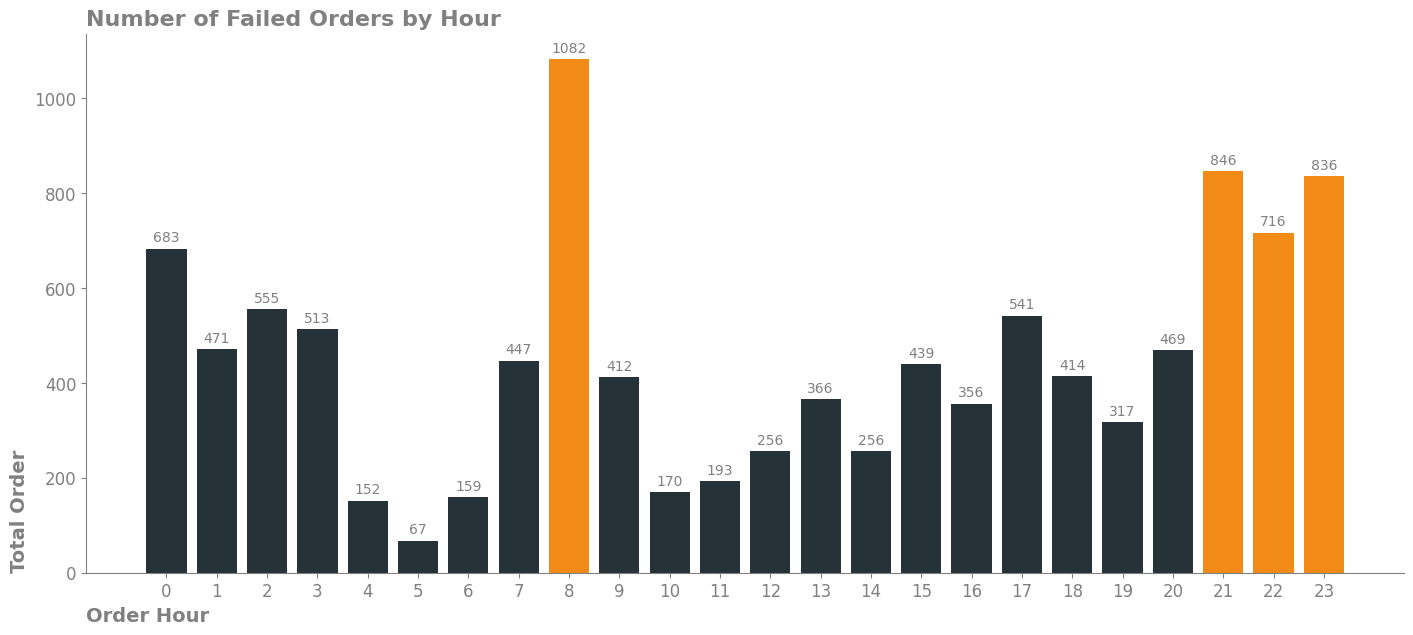

In [28]:
fig,ax=plt.subplots(figsize=(17,7))
barplot_rect=(ax.bar(hourly_canceled_orders['order_hour'],
        height=hourly_canceled_orders['total_failed_orders'],
        color=hourly_canceled_orders['hour_color']))

ax.bar_label(barplot_rect,label_type='edge', color='gray',padding=3)

ax.spines[['top','right']].set_visible(False)
ax.spines[['bottom','left']].set_color('gray')

ax.tick_params(axis='both',colors='gray',labelsize=12)
ax.set_xticks(range(24))

ax.set_xlabel("Order Hour", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Total Order", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title('Number of Failed Orders by Hour',fontsize=16,color='gray',loc='left',weight='bold')

plt.show()

In [29]:
hourly_canceled_customer_driver_not_assigned=(orders.query('order_status_key==4 and is_driver_assigned_key==0')
                                            .groupby('order_hour',as_index=False).agg(total_failed_orders=("order_gk", "count"))
                                            .assign(share_canceled_orders=lambda df: df["total_failed_orders"] / df["total_failed_orders"].sum(),
                                            total_canceled_orders_zscore=lambda df: stats.zscore(df["total_failed_orders"]),
                                            hour_color=lambda df: np.where(df["total_canceled_orders_zscore"].gt(1), "#F28A17", "#253338")))
hourly_canceled_customer_driver_not_assigned


,order_hour,total_failed_orders,share_canceled_orders,total_canceled_orders_zscore,hour_color
0,0,298,0.066281,0.959146,#253338
1,1,219,0.048710,0.274454,#253338
2,2,237,0.052714,0.430460,#253338
3,3,224,0.049822,0.317789,#253338
4,4,50,0.011121,-1.190266,#253338
5,5,15,0.003336,-1.493610,#253338
6,6,67,0.014902,-1.042927,#253338
7,7,164,0.036477,-0.202230,#253338
8,8,413,0.091859,1.955849,#F28A17
9,9,148,0.032918,-0.340901,#253338


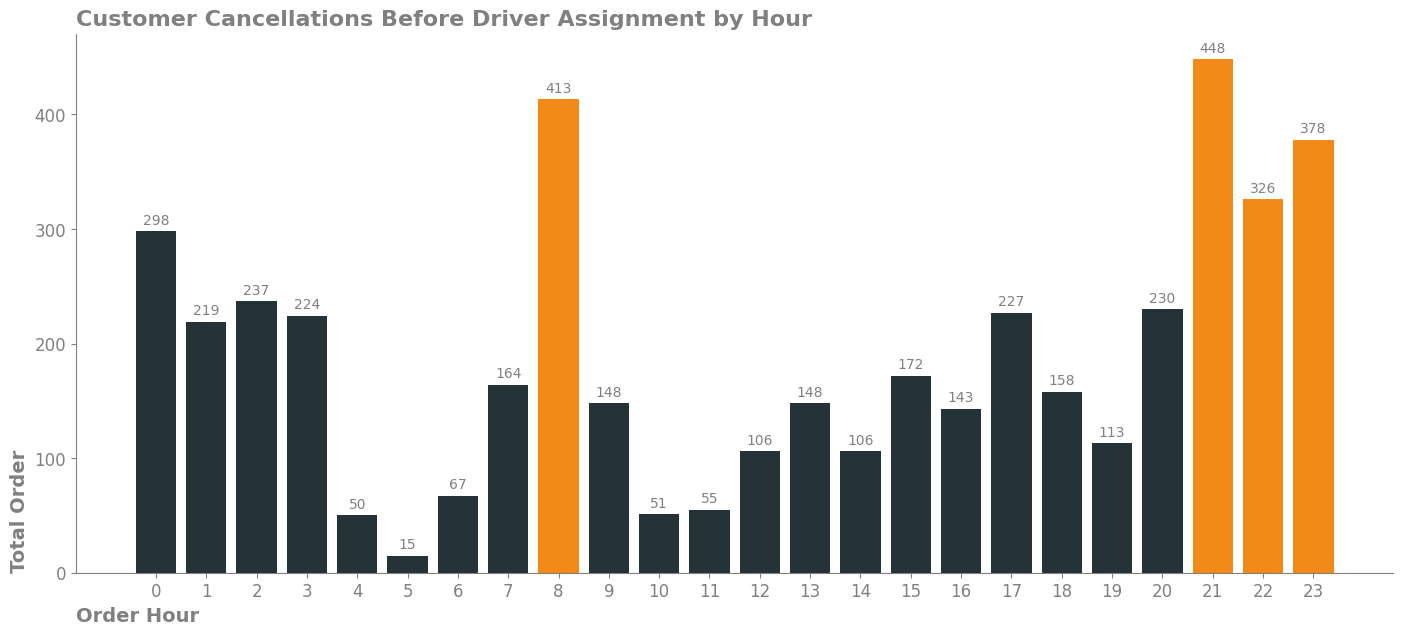

In [30]:
fig,ax=plt.subplots(figsize=(17,7))
barplot_rect=ax.bar(hourly_canceled_customer_driver_not_assigned['order_hour'],
        height=hourly_canceled_customer_driver_not_assigned['total_failed_orders'],
        color=hourly_canceled_customer_driver_not_assigned['hour_color'])

ax.bar_label(barplot_rect,label_type='edge',padding=3, color='gray')

ax.spines[['top','right']].set_visible(False)
ax.spines[['bottom','left']].set_color('gray')

ax.tick_params(axis='both',colors='gray', labelsize=12)
ax.set_xticks(range(24))

ax.set_xlabel("Order Hour", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Total Order", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title('Customer Cancellations Before Driver Assignment by Hour',fontsize=16, color="gray", loc="left", weight="bold")

plt.show()

In [31]:
hourly_canceled_customer_driver_assigned=(orders.query('order_status_key==4 and is_driver_assigned_key==1')
                                        .groupby('order_hour',as_index=False).agg(total_failed_orders=("order_gk", "count"))
                                        .assign(share_canceled_orders=lambda df: df["total_failed_orders"] / df["total_failed_orders"].sum(),
                                        total_canceled_orders_zscore=lambda df: stats.zscore(df["total_failed_orders"]),
                                        hour_color=lambda df: np.where(df["total_canceled_orders_zscore"].gt(1), "#F28A17", "#253338")))

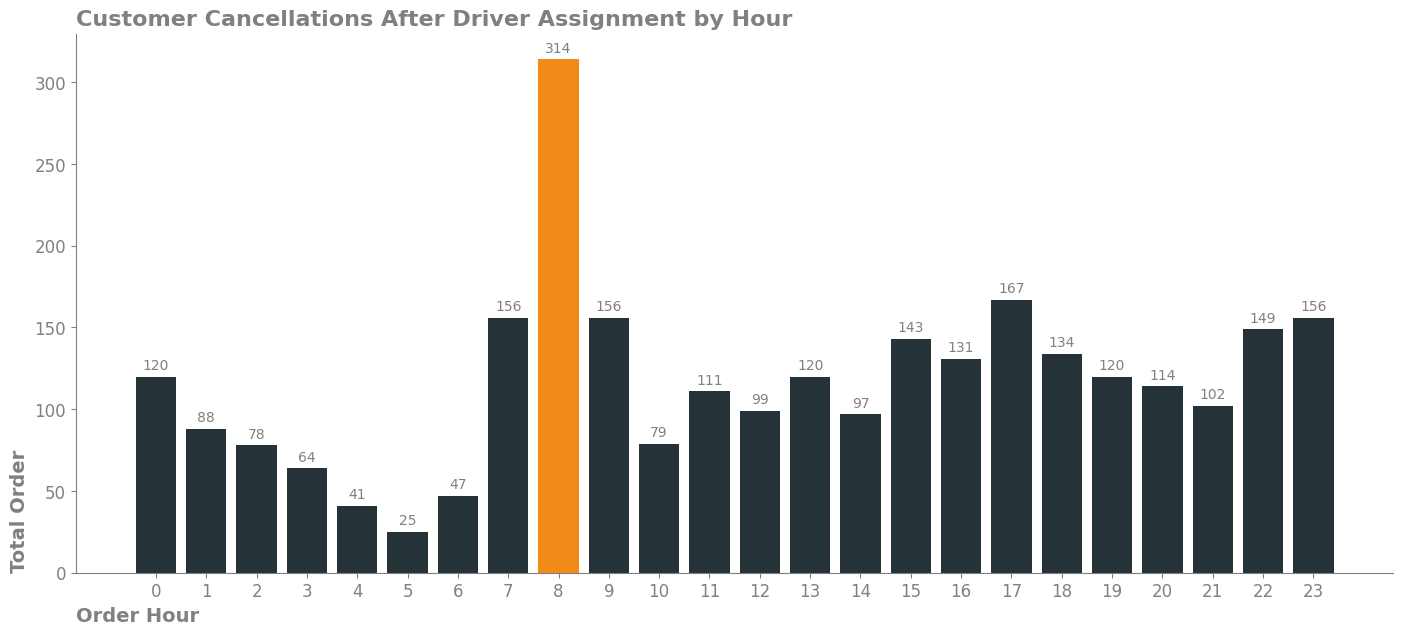

In [32]:
fig,ax=plt.subplots(figsize=(17,7))

barplot_rect = ax.bar(hourly_canceled_customer_driver_assigned['order_hour'],
        height=hourly_canceled_customer_driver_assigned['total_failed_orders'],
        color=hourly_canceled_customer_driver_assigned['hour_color'])

ax.bar_label(barplot_rect, color='gray', label_type='edge',padding=3) 

ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.tick_params(axis='both',labelsize=12, colors='gray')
ax.set_xticks(range(24))

ax.set_xlabel("Order Hour", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Total Order", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title("Customer Cancellations After Driver Assignment by Hour", fontsize=16, color="gray", loc="left", weight="bold")

plt.show()

In [33]:
customer_cancellations_after_ETA=(orders
                                        .query('order_status_key==4 and is_driver_assigned_key==1 and m_order_eta < cancellations_time_in_seconds')
                                        .groupby('order_hour',as_index=False).agg(total_failed_orders=("order_gk", "count"))
                                        .assign(share_canceled_orders=lambda df: df["total_failed_orders"] / df["total_failed_orders"].sum(),
                                        total_canceled_orders_zscore=lambda df: stats.zscore(df["total_failed_orders"]),
                                        hour_color=lambda df: np.where(df["total_canceled_orders_zscore"].gt(1), "#F28A17", "#253338")))

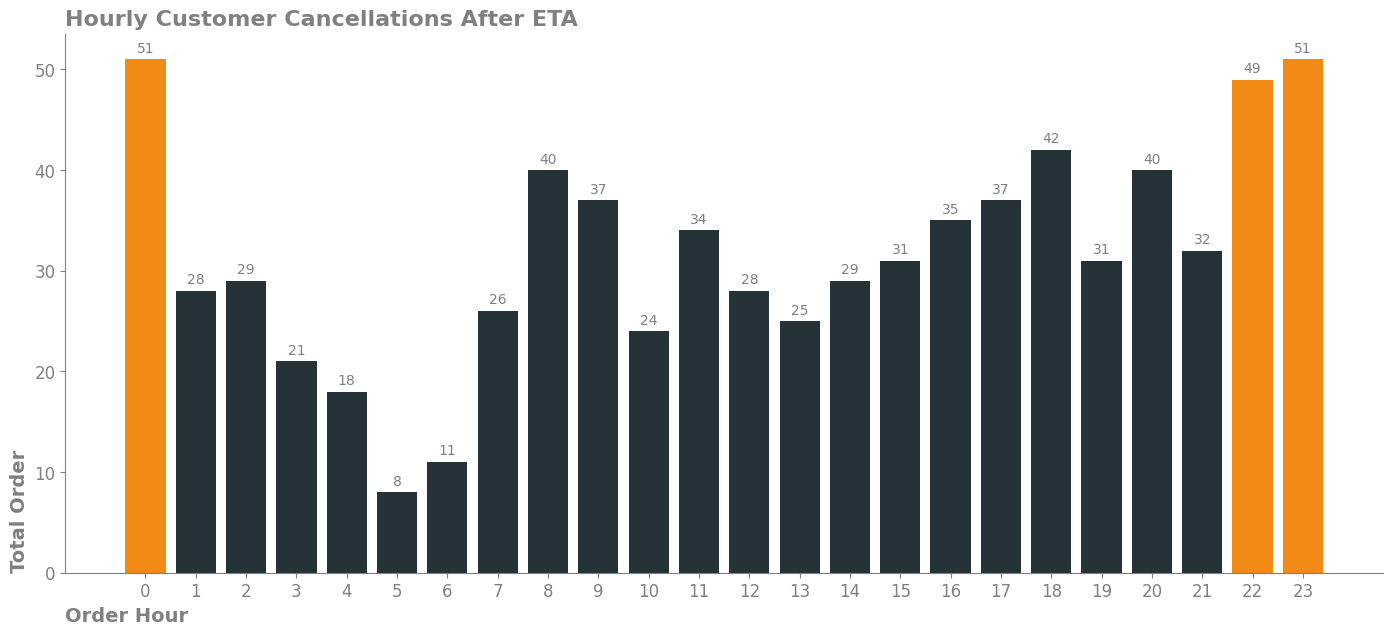

In [34]:
fig,ax=plt.subplots(figsize=(17,7))

barplot_rect = ax.bar(customer_cancellations_after_ETA['order_hour'],
        customer_cancellations_after_ETA['total_failed_orders'],
        color=customer_cancellations_after_ETA['hour_color'])

ax.bar_label(barplot_rect, color='gray', label_type='edge',padding=3) 

ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.tick_params(axis='both',labelsize=12, colors='gray')
ax.set_xticks(range(24))

ax.set_xlabel("Order Hour", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Total Order", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title("Hourly Customer Cancellations After ETA", fontsize=16, color="gray", loc="left", weight="bold")

plt.show()

In [35]:
customer_cancellations_before_ETA=(orders
                                        .query('order_status_key==4 and is_driver_assigned_key==1 and m_order_eta > cancellations_time_in_seconds')
                                        .groupby('order_hour',as_index=False).agg(total_failed_orders=("order_gk", "count"))
                                        .assign(share_canceled_orders=lambda df: df["total_failed_orders"] / df["total_failed_orders"].sum(),
                                        total_canceled_orders_zscore=lambda df: stats.zscore(df["total_failed_orders"]),
                                        hour_color=lambda df: np.where(df["total_canceled_orders_zscore"].gt(1), "#F28A17", "#253338")))

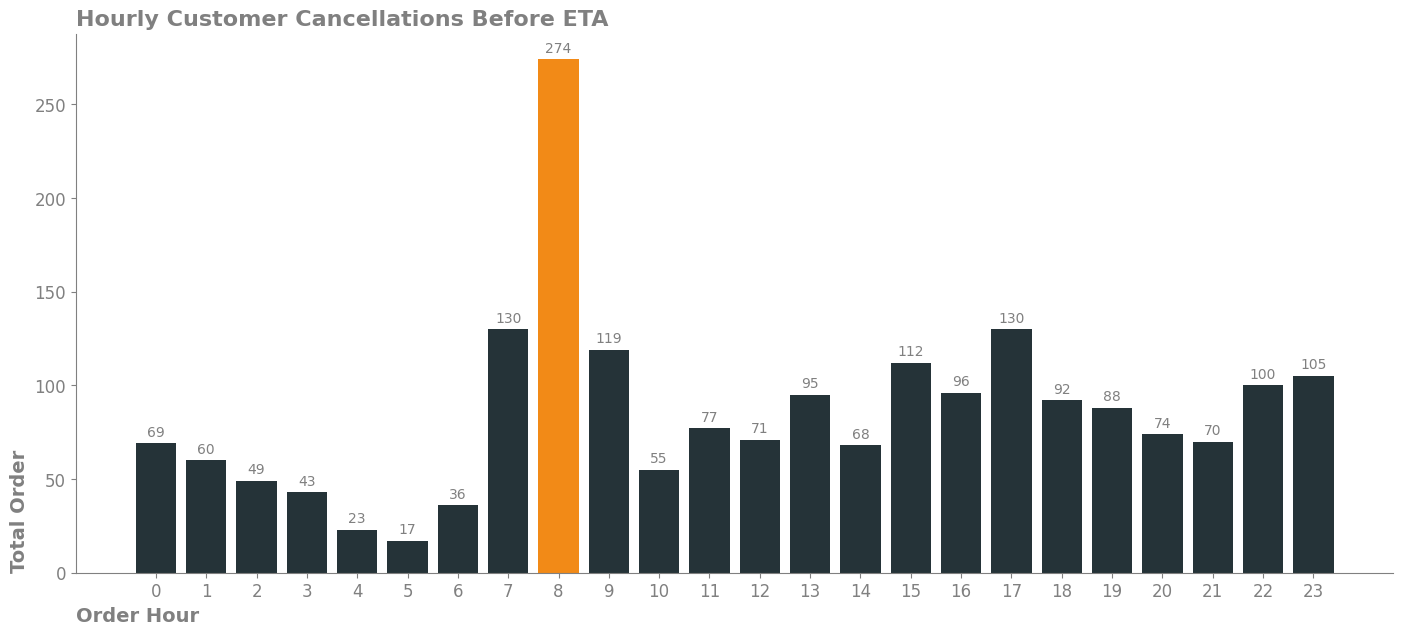

In [36]:
fig,ax=plt.subplots(figsize=(17,7))

barplot_rect = ax.bar(customer_cancellations_before_ETA['order_hour'],
        customer_cancellations_before_ETA['total_failed_orders'],
        color=customer_cancellations_before_ETA['hour_color'])

ax.bar_label(barplot_rect, color='gray', label_type='edge',padding=3) 

ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.tick_params(axis='both',labelsize=12, colors='gray')
ax.set_xticks(range(24))

ax.set_xlabel("Order Hour", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Total Order", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title("Hourly Customer Cancellations Before ETA", fontsize=16, color="gray", loc="left", weight="bold")

plt.show()

In [37]:
system_cancellations=(orders.query('order_status_key==9')
                            .groupby('order_hour',as_index=False).agg(total_failed_orders=("order_gk", "count"))
                            .assign(share_canceled_orders=lambda df: df["total_failed_orders"] / df["total_failed_orders"].sum(),
                            total_canceled_orders_zscore=lambda df: stats.zscore(df["total_failed_orders"]),
                            hour_color=lambda df: np.where(df["total_canceled_orders_zscore"].gt(1), "#F28A17", "#253338")))

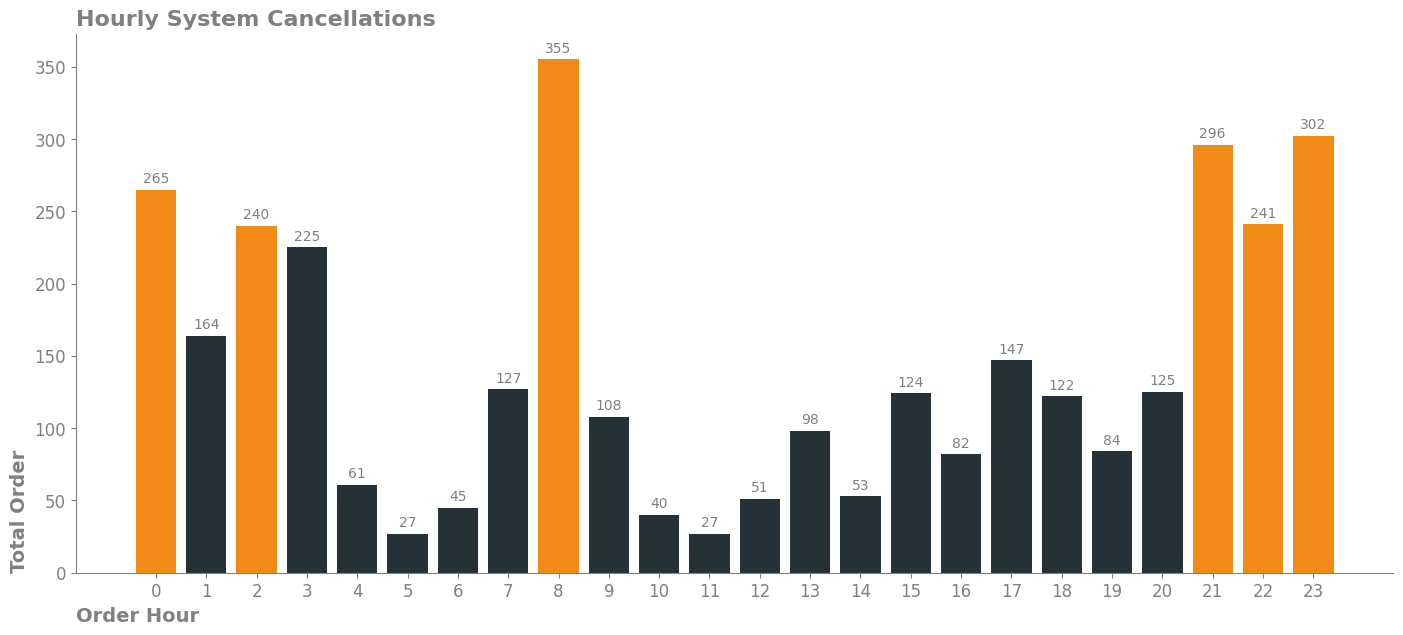

In [38]:
fig,ax=plt.subplots(figsize=(17,7))

barplot_rect = ax.bar(system_cancellations['order_hour'],
        height=system_cancellations['total_failed_orders'],
        color=system_cancellations['hour_color'])

ax.bar_label(barplot_rect, color='gray', label_type='edge',padding=3) 

ax.spines[['top','right']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.tick_params(axis='both',labelsize=12, colors='gray')
ax.set_xticks(range(24))

ax.set_xlabel("Order Hour", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Total Order", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title("Hourly System Cancellations", fontsize=16, color="gray", loc="left", weight="bold")

plt.show()

# Part 3
Plot the average time to cancellation with and without driver, by the hour. If there are any outliers in the data, it would be better to remove them. Can we draw any conclusions from this plot?

In [39]:
(pd.pivot_table(data=orders,
                values='cancellations_time_in_seconds',
                columns='is_driver_assigned_key',
                index='order_hour',
                aggfunc='mean')
                .reset_index()
                .rename(columns={0: "driver_not_assigned", 1: "driver_assigned"})
                .assign(cancelation_time_changed=lambda df: df['driver_assigned']/df['driver_not_assigned']))

is_driver_assigned_key,order_hour,driver_not_assigned,driver_assigned,cancelation_time_changed
0,0,111.557047,293.616667,2.631987
1,1,98.132420,247.715909,2.524302
2,2,106.438819,303.307692,2.849597
3,3,104.361607,292.640625,2.804102
4,4,90.000000,243.219512,2.702439
5,5,121.800000,314.400000,2.581281
6,6,124.955224,272.553191,2.181207
7,7,112.628049,188.891026,1.677122
8,8,120.702179,189.025478,1.566049
9,9,120.000000,216.493590,1.804113


In [40]:
orders['cancellations_time_in_seconds'].describe()

count    7307.000000
mean      157.892021
std       213.366963
min         3.000000
25%        45.000000
50%        98.000000
75%       187.500000
max      4303.000000
Name: cancellations_time_in_seconds, dtype: float64

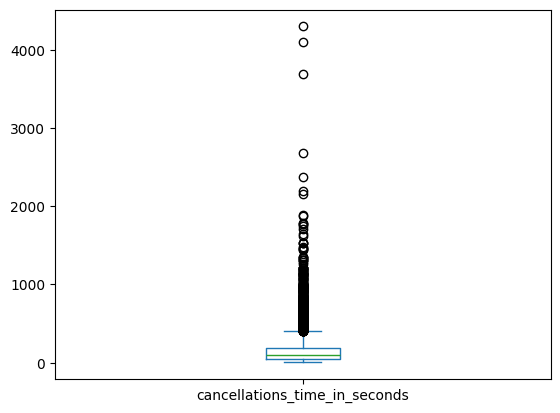

In [41]:
orders['cancellations_time_in_seconds'].plot(kind='box')
plt.show()

- z-score

In [42]:
normal_cancellation_order_zscore=(orders
                                .assign(outlier_zscore=lambda df: stats.zscore(df['cancellations_time_in_seconds'],nan_policy='omit'))
                                .query('outlier_zscore < 3 and outlier_zscore > -3'))

In [43]:
normal_cancellation_order_zscore

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,order_hour,outlier_zscore
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,18,0.187989
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0,20,-0.140106
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0,12,-0.524447
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0,13,-0.449454
9,06:33:52,-0.976216,51.433202,NaN,3000582765616,4,0,78.0,6,-0.374460
...,...,...,...,...,...,...,...,...,...,...
10711,13:11:35,-0.975372,51.457846,NaN,3000599186906,4,0,36.0,13,-0.571318
10712,13:13:55,-0.975372,51.457846,NaN,3000599186962,4,0,4.0,13,-0.721305
10713,13:17:21,-0.972926,51.457693,60.0,3000599187034,4,1,34.0,13,-0.580692
10714,13:16:28,-0.975372,51.457846,NaN,3000599187024,4,0,6.0,13,-0.711930


In [44]:
(pd.pivot_table(data=normal_cancellation_order_zscore,
                index='order_hour',
                columns='is_driver_assigned_key',
                values='cancellations_time_in_seconds',
                aggfunc='mean')
                .reset_index()
                .rename(columns={0: "driver_not_assigned", 1: "driver_assigned"})
                .assign(cancelation_time_changed=lambda df: df["driver_assigned"] / df["driver_not_assigned"]))


is_driver_assigned_key,order_hour,driver_not_assigned,driver_assigned,cancelation_time_changed
0,0,109.127946,221.190909,2.026895
1,1,98.132420,199.190476,2.029813
2,2,106.438819,232.816901,2.187331
3,3,104.361607,200.631579,1.922465
4,4,90.000000,209.461538,2.327350
5,5,121.800000,168.217391,1.381095
6,6,108.984848,170.466667,1.564132
7,7,112.628049,175.457516,1.557849
8,8,118.936893,162.154098,1.363362
9,9,120.000000,190.695364,1.589128


<Axes: >

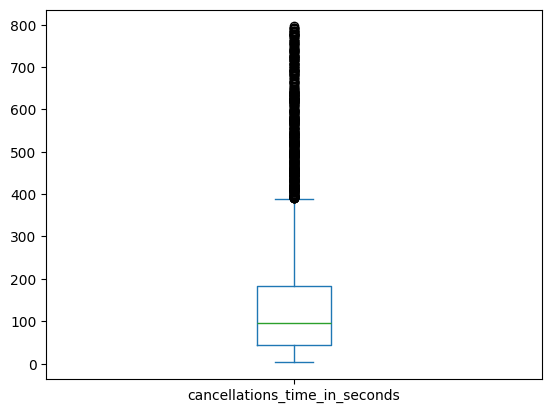

In [45]:
normal_cancellation_order_zscore['cancellations_time_in_seconds'].plot(kind='box')

- Interquartile Outlier Detection

In [46]:
q1_cancellation_time = orders["cancellations_time_in_seconds"].quantile(0.25)
q3_cancellation_time = orders["cancellations_time_in_seconds"].quantile(0.75)

IQR= q3_cancellation_time - q1_cancellation_time

lower_bound = q1_cancellation_time - 1.5 * IQR
upper_bound = q3_cancellation_time + 1.5 * IQR

normal_cancellation_order_iqr =(orders.assign(outlier_iqr=lambda df: np.where(((df["cancellations_time_in_seconds"]>upper_bound) | (df["cancellations_time_in_seconds"]<lower_bound)),"outlier", "normal"))
                                .query("outlier_iqr == 'normal'"))

normal_cancellation_order_iqr

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,order_hour,outlier_iqr
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,18,normal
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0,20,normal
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0,12,normal
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0,13,normal
4,21:24:45,-0.967605,51.458236,NaN,3000583140877,9,0,NaN,21,normal
...,...,...,...,...,...,...,...,...,...,...
10711,13:11:35,-0.975372,51.457846,NaN,3000599186906,4,0,36.0,13,normal
10712,13:13:55,-0.975372,51.457846,NaN,3000599186962,4,0,4.0,13,normal
10713,13:17:21,-0.972926,51.457693,60.0,3000599187034,4,1,34.0,13,normal
10714,13:16:28,-0.975372,51.457846,NaN,3000599187024,4,0,6.0,13,normal


In [47]:
(pd.pivot_table(data=normal_cancellation_order_iqr,
                index='order_hour',
                columns='is_driver_assigned_key',
                values='cancellations_time_in_seconds',
                aggfunc='mean')
                .reset_index()
                .rename(columns={0: "driver_not_assigned", 1: "driver_assigned"})
                .assign(cancelation_time_changed=lambda df: df["driver_assigned"] / df["driver_not_assigned"]))


is_driver_assigned_key,order_hour,driver_not_assigned,driver_assigned,cancelation_time_changed
0,0,103.453925,146.131868,1.412531
1,1,98.132420,132.985915,1.355168
2,2,101.205128,140.527273,1.388539
3,3,102.174888,115.326087,1.128713
4,4,90.000000,121.125000,1.345833
5,5,121.800000,100.368421,0.824043
6,6,101.384615,89.675676,0.884510
7,7,108.549383,122.962406,1.132778
8,8,110.412346,127.540925,1.155133
9,9,108.724138,127.781955,1.175286


<Axes: >

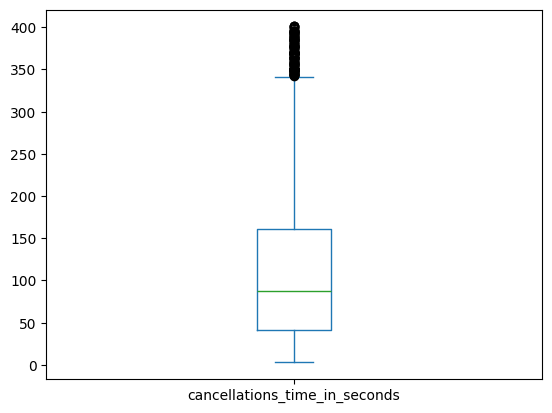

In [48]:
normal_cancellation_order_iqr['cancellations_time_in_seconds'].plot(kind='box')

# Skewness

In [49]:
orders['cancellations_time_in_seconds'].skew()

np.float64(5.453260756895023)

In [50]:
normal_cancellation_order_zscore['cancellations_time_in_seconds'].skew()

np.float64(2.114367503471961)

In [51]:
normal_cancellation_order_iqr['cancellations_time_in_seconds'].skew()

np.float64(0.9847230101306617)

# Part 4.
Plot the distribution of average ETA by hours. How can this plot be explained?

In [52]:
hourly_mean_eta = (orders.groupby("order_hour", as_index=False).agg(mean_eta=("m_order_eta", "mean"))
                        .assign(eta_zscore=lambda df: stats.zscore(df["mean_eta"]),
                                hour_color=lambda df: np.where(df["eta_zscore"]>1, "#F28A17", "#253338"),
                                mean_eta=lambda df: np.round(df["mean_eta"], 0)))

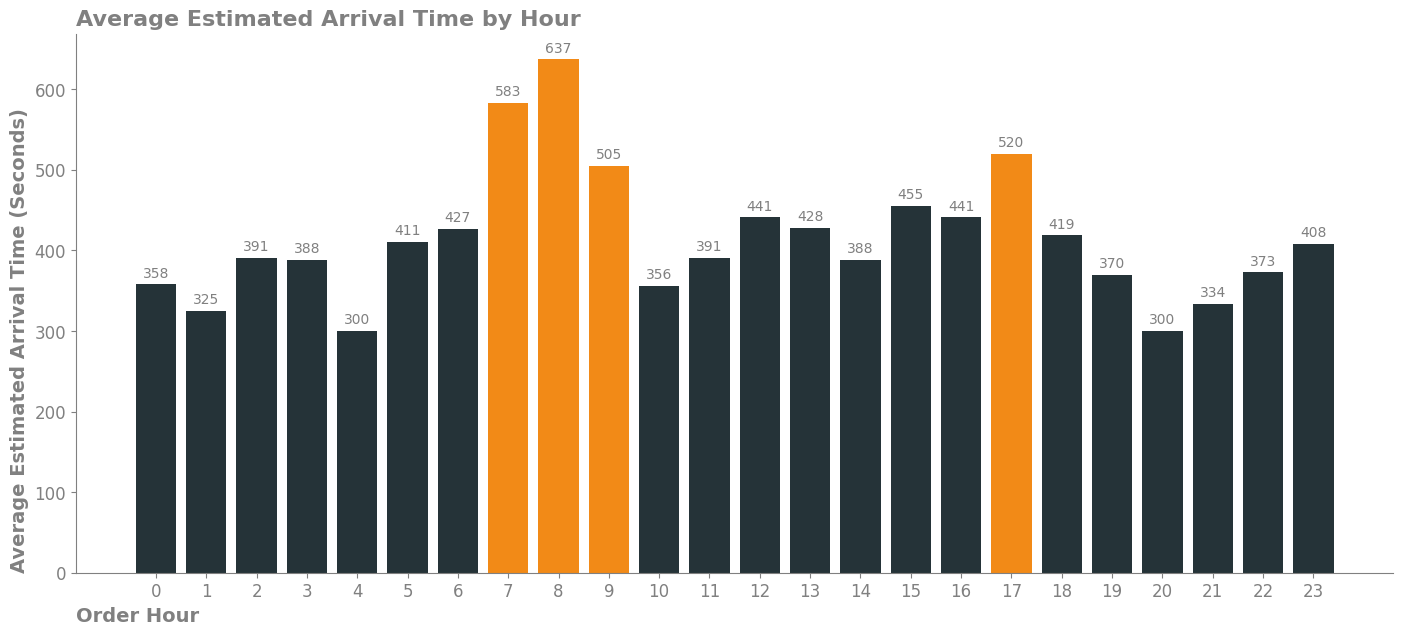

In [53]:
fig, ax = plt.subplots(figsize=(17, 7))

barplot_rect = ax.bar(hourly_mean_eta["order_hour"],
                hourly_mean_eta["mean_eta"],
                color=hourly_mean_eta["hour_color"])

ax.bar_label(barplot_rect, label_type="edge", color="gray", padding=3)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.tick_params(axis="both", colors="gray", labelsize=12)
ax.set_xticks(range(0, 24))

ax.set_xlabel("Order Hour", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Average Estimated Arrival Time (Seconds)", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title("Average Estimated Arrival Time by Hour", fontsize=16, color="gray", loc="left", weight="bold")

plt.show()

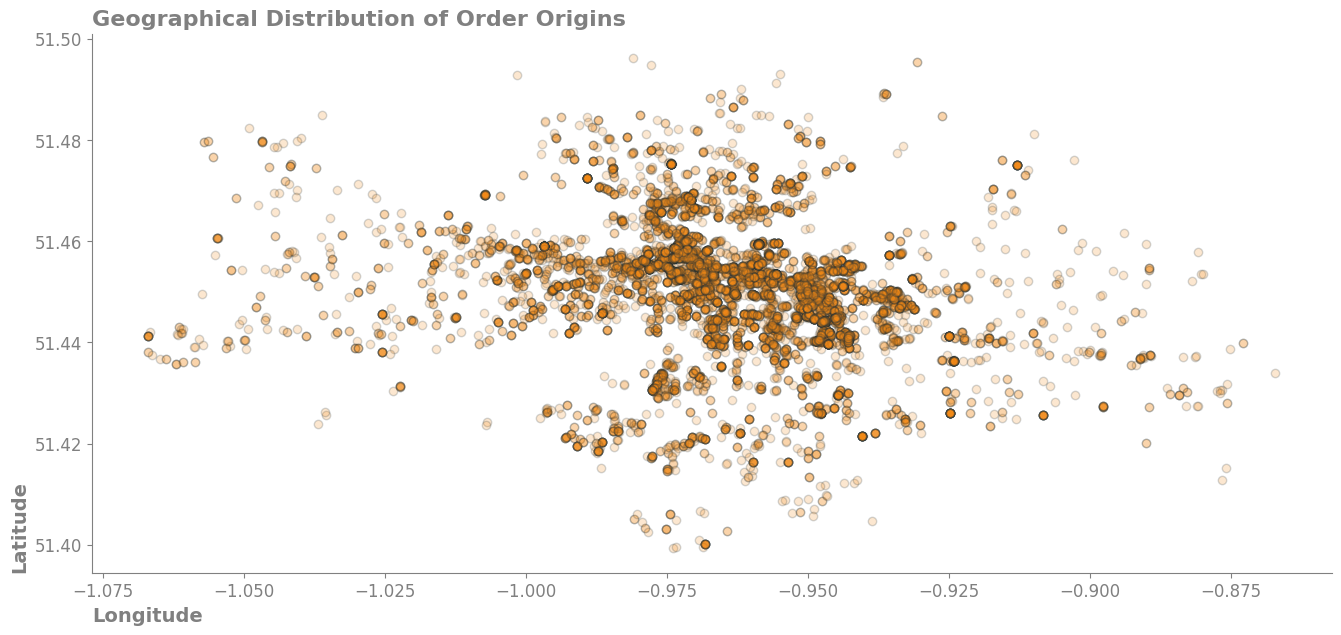

In [54]:
fig, ax = plt.subplots(figsize=(16, 7))
ax.scatter(orders["origin_longitude"],
        orders["origin_latitude"],
        color="#F28A17",
        edgecolors="#253338",
        alpha=0.2)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.tick_params(axis="both", colors="gray", labelsize=12)

ax.set_xlabel("Longitude", fontsize=14, color="gray", loc="left", weight="bold")
ax.set_ylabel("Latitude", fontsize=14, color="gray", loc="bottom", weight="bold")
ax.set_title("Geographical Distribution of Order Origins", fontsize=16, color="gray", loc="left", weight="bold")

plt.show()